In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../artifacts/raw/data.csv")

In [3]:
df.head()

,Patient_ID,Country,Age,Gender,Cancer_Stage,Tumor_Size_mm,Family_History,Smoking_History,Alcohol_Consumption,Obesity_BMI,...,Survival_5_years,Mortality,Healthcare_Costs,Incidence_Rate_per_100K,Mortality_Rate_per_100K,Urban_or_Rural,Economic_Classification,Healthcare_Access,Insurance_Status,Survival_Prediction
0,1,UK,77,M,Localized,69,No,No,Yes,Overweight,...,Yes,No,54413,50,5,Urban,Developed,Moderate,Insured,Yes
1,2,UK,59,M,Localized,33,No,No,No,Overweight,...,Yes,No,76553,37,25,Urban,Developing,High,Uninsured,Yes
2,3,Japan,66,M,Regional,17,No,Yes,No,Normal,...,Yes,No,62805,54,27,Urban,Developed,Moderate,Uninsured,No
3,4,USA,83,M,Regional,14,No,No,No,Obese,...,Yes,No,89393,45,11,Urban,Developed,Moderate,Insured,Yes
4,5,France,66,M,Localized,34,No,Yes,No,Normal,...,Yes,No,66425,15,27,Urban,Developing,High,Insured,Yes


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167497 entries, 0 to 167496
Data columns (total 28 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   Patient_ID                  167497 non-null  int64 
 1   Country                     167497 non-null  object
 2   Age                         167497 non-null  int64 
 3   Gender                      167497 non-null  object
 4   Cancer_Stage                167497 non-null  object
 5   Tumor_Size_mm               167497 non-null  int64 
 6   Family_History              167497 non-null  object
 7   Smoking_History             167497 non-null  object
 8   Alcohol_Consumption         167497 non-null  object
 9   Obesity_BMI                 167497 non-null  object
 10  Diet_Risk                   167497 non-null  object
 11  Physical_Activity           167497 non-null  object
 12  Diabetes                    167497 non-null  object
 13  Inflammatory_Bowel_Disease  1

In [5]:
df.columns

Index(['Patient_ID', 'Country', 'Age', 'Gender', 'Cancer_Stage',
       'Tumor_Size_mm', 'Family_History', 'Smoking_History',
       'Alcohol_Consumption', 'Obesity_BMI', 'Diet_Risk', 'Physical_Activity',
       'Diabetes', 'Inflammatory_Bowel_Disease', 'Genetic_Mutation',
       'Screening_History', 'Early_Detection', 'Treatment_Type',
       'Survival_5_years', 'Mortality', 'Healthcare_Costs',
       'Incidence_Rate_per_100K', 'Mortality_Rate_per_100K', 'Urban_or_Rural',
       'Economic_Classification', 'Healthcare_Access', 'Insurance_Status',
       'Survival_Prediction'],
      dtype='object')

In [6]:
df["Country"].value_counts()

Country
USA             25927
China           17525
South Korea     14107
Japan           13924
UK              12276
Germany         12258
India           10479
France          10426
Brazil          10399
Canada           8819
Italy            8795
Australia        6877
South Africa     5172
Nigeria          3551
Pakistan         3549
New Zealand      3413
Name: count, dtype: int64

In [7]:
df["Gender"].value_counts()

Gender
M    100686
F     66811
Name: count, dtype: int64

In [8]:
df["Cancer_Stage"].value_counts()

Cancer_Stage
Regional      66981
Localized     66799
Metastatic    33717
Name: count, dtype: int64

In [22]:
df["Tumor_Size_mm"].value_counts()
df["Mortality"].value_counts()

Mortality
No     100354
Yes     67143
Name: count, dtype: int64

In [ ]:
df["Family_History"].value_counts()  # Previous Generations have suffered the same

Family_History
No     117184
Yes     50313
Name: count, dtype: int64

In [21]:
df['Alcohol_Consumption'].value_counts()   # Similarly we can check for the other features
df['Diet_Risk'].value_counts()
df['Physical_Activity'].value_counts()
df['Diabetes'].value_counts()
df['Inflammatory_Bowel_Disease'].value_counts()  # Irritable Gut
df['Genetic_Mutation'].value_counts()  # Sudden change in Genes, possibly leading to the first time in history
df['Screening_History'].value_counts()
df['Early_Detection'].value_counts()
df['Treatment_Type'].value_counts()

Treatment_Type
Surgery         66934
Chemotherapy    50443
Combination     33276
Radiotherapy    16844
Name: count, dtype: int64

In [24]:
df['Urban_or_Rural'].value_counts()
df['Economic_Classification'].value_counts()

Economic_Classification
Developed     100367
Developing     67130
Name: count, dtype: int64

In [27]:
df["Healthcare_Access"].value_counts()
df["Insurance_Status"].value_counts()
df["Survival_Prediction"].value_counts()

Survival_Prediction
Yes    100437
No      67060
Name: count, dtype: int64

In [29]:
#df.isnull().sum()      ## All perfect, no null/missing values


In [30]:
df.duplicated().sum()

np.int64(0)

In [32]:
df.shape

(167497, 28)

In [34]:
df.describe()  # Patient ID not required for Model, just for identification

,Patient_ID,Age,Tumor_Size_mm,Healthcare_Costs,Incidence_Rate_per_100K,Mortality_Rate_per_100K
count,167497.000000,167497.00000,167497.000000,167497.000000,167497.000000,167497.000000
mean,83749.000000,69.20078,42.005708,72452.168099,34.531562,17.023875
std,48352.363357,11.87247,21.672206,27402.779597,14.447970,7.208766
min,1.000000,30.00000,5.000000,25000.000000,10.000000,5.000000
25%,41875.000000,59.00000,23.000000,48760.000000,22.000000,11.000000
50%,83749.000000,69.00000,42.000000,72344.000000,35.000000,17.000000
75%,125623.000000,79.00000,61.000000,96227.000000,47.000000,23.000000
max,167497.000000,89.00000,79.000000,119999.000000,59.000000,29.000000


In [36]:
df.columns

Index(['Patient_ID', 'Country', 'Age', 'Gender', 'Cancer_Stage',
       'Tumor_Size_mm', 'Family_History', 'Smoking_History',
       'Alcohol_Consumption', 'Obesity_BMI', 'Diet_Risk', 'Physical_Activity',
       'Diabetes', 'Inflammatory_Bowel_Disease', 'Genetic_Mutation',
       'Screening_History', 'Early_Detection', 'Treatment_Type',
       'Survival_5_years', 'Mortality', 'Healthcare_Costs',
       'Incidence_Rate_per_100K', 'Mortality_Rate_per_100K', 'Urban_or_Rural',
       'Economic_Classification', 'Healthcare_Access', 'Insurance_Status',
       'Survival_Prediction'],
      dtype='object')

### VISUALIZATIONS

In [35]:
plt.figure(figsize=(8,5))

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

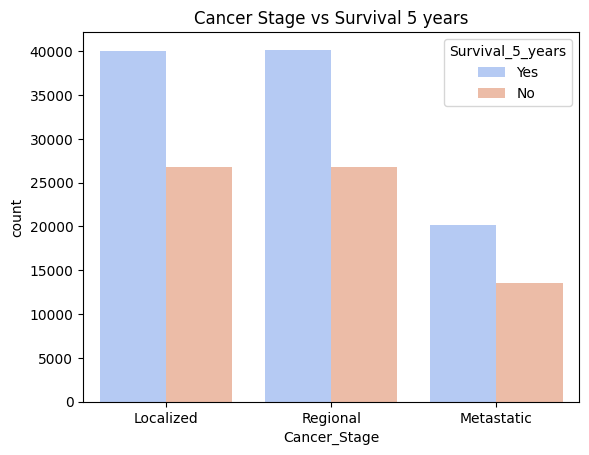

In [37]:
sns.countplot(x="Cancer_Stage",hue="Survival_5_years",data=df,palette="coolwarm")
plt.title("Cancer Stage vs Survival 5 years")
plt.show()

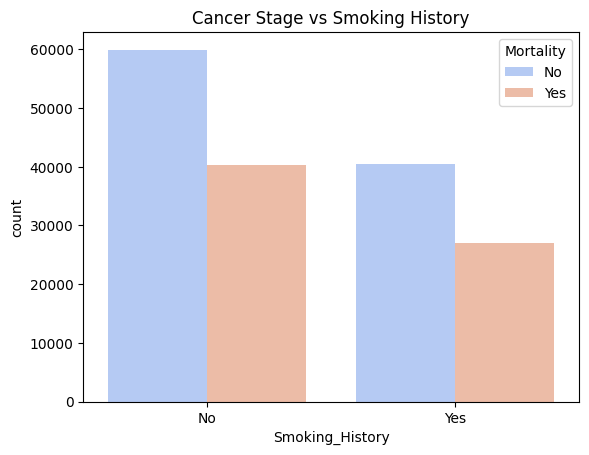

In [40]:
sns.countplot(x="Smoking_History",hue="Mortality",data=df,palette="coolwarm")
plt.title("Cancer Stage vs Smoking History")
plt.show()

C:\Users\Rhitwik Prakash\AppData\Local\Temp\ipykernel_10436\1951728067.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cancer_Stage",y='Tumor_Size_mm',data=df,palette="coolwarm")


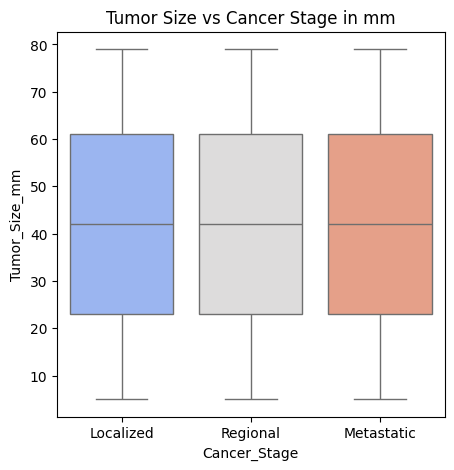

In [44]:
plt.figure(figsize=(5,5))
sns.boxplot(x="Cancer_Stage",y='Tumor_Size_mm',data=df,palette="coolwarm")
plt.title("Tumor Size vs Cancer Stage in mm")
plt.show()

C:\Users\Rhitwik Prakash\AppData\Local\Temp\ipykernel_10436\4111087398.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="Cancer_Stage", y="Tumor_Size_mm", data=df, palette="coolwarm")


Text(0.5, 1.0, 'Tumor Size Distribution by Cancer Stage')

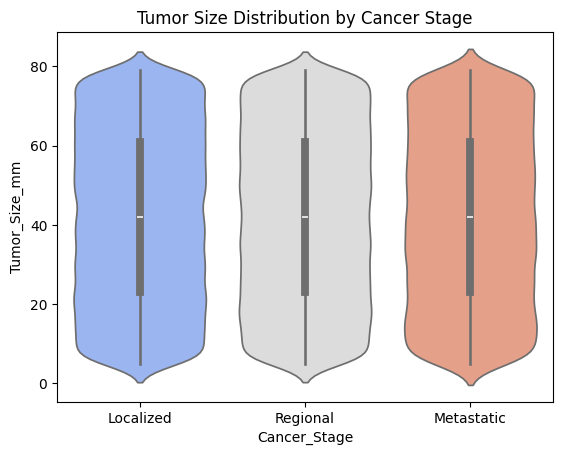

In [45]:
sns.violinplot(x="Cancer_Stage", y="Tumor_Size_mm", data=df, palette="coolwarm")
plt.title("Tumor Size Distribution by Cancer Stage")

C:\Users\Rhitwik Prakash\AppData\Local\Temp\ipykernel_10436\1679937625.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Survival_Prediction",y='Healthcare_Costs',data=df,palette="coolwarm")


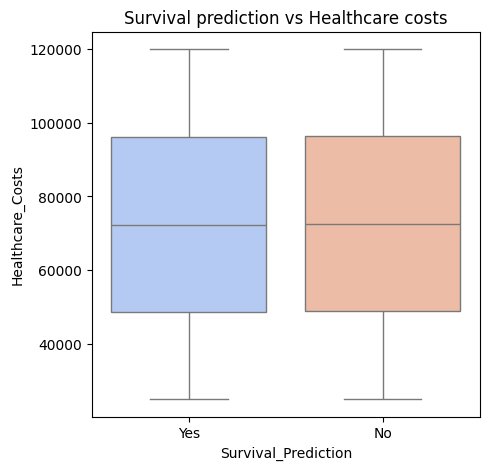

In [46]:
plt.figure(figsize=(5,5))
sns.boxplot(x="Survival_Prediction",y='Healthcare_Costs',data=df,palette="coolwarm")
plt.title("Survival prediction vs Healthcare costs")
plt.show()

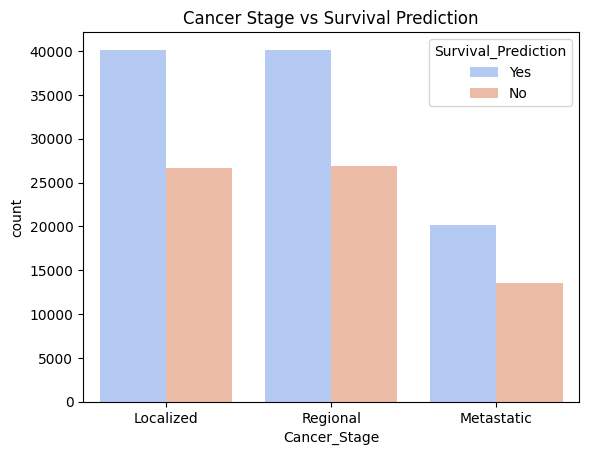

In [47]:
sns.countplot(x="Cancer_Stage",hue="Survival_Prediction",data=df,palette="coolwarm")
plt.title("Cancer Stage vs Survival Prediction")
plt.show()

### DATA PREPROCESSING

In [48]:
df = df.drop(columns=['Patient_ID'])


In [49]:
X = df.drop(columns=['Survival_Prediction'])
Y = df["Survival_Prediction"]

In [50]:
X.shape

(167497, 26)

In [51]:
Y.shape

(167497,)

In [52]:
categorical_cols = X.select_dtypes(include=['object']).columns

In [54]:
categorical_cols
len(categorical_cols)

21

In [55]:
from sklearn.preprocessing import LabelEncoder

In [56]:
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])
    label_encoders[col] = le  # Storing label encoders inside dictionary to access which label is encoded to which number

In [57]:
X.head()

,Country,Age,Gender,Cancer_Stage,Tumor_Size_mm,Family_History,Smoking_History,Alcohol_Consumption,Obesity_BMI,Diet_Risk,...,Treatment_Type,Survival_5_years,Mortality,Healthcare_Costs,Incidence_Rate_per_100K,Mortality_Rate_per_100K,Urban_or_Rural,Economic_Classification,Healthcare_Access,Insurance_Status
0,14,77,1,0,69,0,0,1,2,1,...,1,1,0,54413,50,5,1,0,2,0
1,14,59,1,0,33,0,0,0,2,2,...,0,1,0,76553,37,25,1,1,0,1
2,8,66,1,2,17,0,1,0,0,1,...,0,1,0,62805,54,27,1,0,2,1
3,15,83,1,2,14,0,0,0,1,0,...,3,1,0,89393,45,11,1,0,2,0
4,4,66,1,0,34,0,1,0,0,1,...,3,1,0,66425,15,27,1,1,0,0


In [ ]:
X.info()  # Transformation of all object type columns into integer type

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167497 entries, 0 to 167496
Data columns (total 26 columns):
 #   Column                      Non-Null Count   Dtype
---  ------                      --------------   -----
 0   Country                     167497 non-null  int64
 1   Age                         167497 non-null  int64
 2   Gender                      167497 non-null  int64
 3   Cancer_Stage                167497 non-null  int64
 4   Tumor_Size_mm               167497 non-null  int64
 5   Family_History              167497 non-null  int64
 6   Smoking_History             167497 non-null  int64
 7   Alcohol_Consumption         167497 non-null  int64
 8   Obesity_BMI                 167497 non-null  int64
 9   Diet_Risk                   167497 non-null  int64
 10  Physical_Activity           167497 non-null  int64
 11  Diabetes                    167497 non-null  int64
 12  Inflammatory_Bowel_Disease  167497 non-null  int64
 13  Genetic_Mutation            167497 non-null 

In [59]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [63]:
# X_train
# X_test
# Y_train
# Y_test    # CHECK AS NEEDED

In [64]:
from sklearn.feature_selection import chi2, SelectKBest

In [66]:
## CHI-SQUARE TEST
X_cat = X_train.select_dtypes(include=['int64','float64'])
chi2_selector = SelectKBest(score_func=chi2, k="all")
chi2_selector.fit(X_cat,Y_train)

,score_func,<function chi...001CA37A61510>
,k,'all'


In [71]:
chi2_scores = pd.DataFrame({
    'Feature': X_cat.columns,
    'Chi2 Score' : chi2_selector.scores_
}).sort_values(by='Chi2 Score', ascending=False)

chi2_scores  # To see the best 5 features

,Feature,Chi2 Score
19,Healthcare_Costs,2097.430133
4,Tumor_Size_mm,7.971461
16,Treatment_Type,4.987144
11,Diabetes,2.103967
21,Mortality_Rate_per_100K,1.963077
25,Insurance_Status,1.464241
3,Cancer_Stage,1.281849
14,Screening_History,1.159519
0,Country,0.883425
24,Healthcare_Access,0.713346


In [76]:
top_features = chi2_scores.head(5)["Feature"].tolist()
top_features

['Healthcare_Costs',
 'Tumor_Size_mm',
 'Treatment_Type',
 'Diabetes',
 'Mortality_Rate_per_100K']

In [78]:
X = X[top_features]
X

,Healthcare_Costs,Tumor_Size_mm,Treatment_Type,Diabetes,Mortality_Rate_per_100K
0,54413,69,1,0,5
1,76553,33,0,0,25
2,62805,17,0,0,27
3,89393,14,3,0,11
4,66425,34,3,0,27
...,...,...,...,...,...
167492,100924,49,1,0,13
167493,90331,29,0,0,22
167494,90631,62,0,1,19
167495,114385,35,3,1,23


In [79]:
Y.shape

(167497,)

In [80]:
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42, stratify=Y)

In [84]:
# X_train.shape  # (133997,5)
# X_test.shape
Y_train.shape
# Y_test.shape

(133997,)

### MODEL BUILDING

In [87]:
''' For MODEL BUILDING
StandardScaler standardizes features by transforming them to have a mean of 0 and a standard deviation of 1. 
This is also known as Z-score normalization or standardization. The formula for standardization is: z = (x - μ) / σ 
'''
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [89]:
from sklearn.ensemble import GradientBoostingClassifier
gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(X_train,Y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [92]:
Y_pred = gb.predict(X_test)

In [95]:
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

In [97]:
accuracy = accuracy_score(Y_test, Y_pred)
accuracy

0.5995223880597015

In [99]:
report = classification_report(Y_test, Y_pred)
print(report)

              precision    recall  f1-score   support

          No       0.44      0.00      0.00     13412
         Yes       0.60      1.00      0.75     20088

    accuracy                           0.60     33500
   macro avg       0.52      0.50      0.38     33500
weighted avg       0.54      0.60      0.45     33500



In [104]:
Y_proba = gb.predict_proba(X_test)[:,1] if len(Y.unique())==2 else None
roc_auc_score(Y_test, Y_proba)   # Works only on binary classification

0.49967731082550826

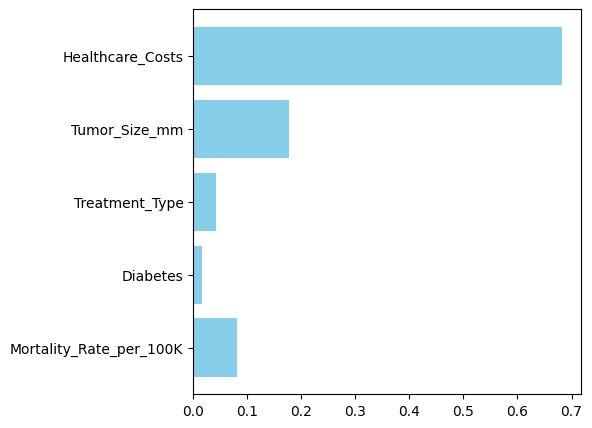

In [107]:
plt.figure(figsize=(5,5))
plt.barh(top_features, gb.feature_importances_, color = "skyblue")   # Gradient Boosting has its own feature importances, uses Decision Tree
plt.gca().invert_yaxis()

### TESTING

In [111]:
X.columns

Index(['Healthcare_Costs', 'Tumor_Size_mm', 'Treatment_Type', 'Diabetes',
       'Mortality_Rate_per_100K'],
      dtype='object')

In [116]:
test_array = np.array([0,0,0,0,0]).reshape(1,-1)   # Encoding values entered, if HealthCare cost=0, there is no cancer!!

In [117]:
gb.predict(test_array)

array(['Yes'], dtype=object)

In [118]:
test_array = np.array([2000,0,0,0,0]).reshape(1,-1)   # Encoding values entered, if HealthCare cost=0, there is no cancer!!

In [119]:
gb.predict(test_array)

array(['No'], dtype=object)

In [ ]:
## Scaler..
## Model..     during Model Processing and Training